# Forecast store sales with a GRU

Start with **Restart Kernel and Run All Cells**. The first run trains on the
competition data in `data/raw`, measures accuracy on 16 days of known sales,
then forecasts the 16 days Kaggle asks for.

A **series** is one store and product family, such as grocery sales at store 1.
A **training example** uses the 56 days before a forecast date to predict the
following 16 days for one series. A gated recurrent unit (GRU) is a recurrent
neural network that reads those 56 days in order and updates a hidden state as
it goes. A shared model learns patterns across all store–family pairs.

## Configure the run

Set `quick_run = True` to practice with a smaller run. It samples fewer
training dates and runs for one **epoch**, which is one pass through the
selected examples. Set it back to `False` for the full run.

In [1]:
from datetime import timedelta
from pathlib import Path

import numpy as np
import polars as pl
import torch
from torch import nn

quick_run = False
lookback = 56
epochs = 1 if quick_run else 50
origin_stride = 20 if quick_run else 5
batch_size = 1024
learning_rate = 0.0001
gru_hidden_size = 32
seed = 42

feature_groups = ("transactions", "calendar", "holidays", "oil", "store", "last_year")
transaction_window = 56
impute_missing_inputs = True
embedding_size = 16
annual_lag = 364
days_per_week = 7
baseline_weeks = 4

In [2]:
# Validate settings and prepare paths and device
if lookback < baseline_weeks * days_per_week:
    raise ValueError("Use a lookback that covers the full same-weekday baseline.")
if min(epochs, batch_size, origin_stride, gru_hidden_size) < 1:
    raise ValueError("Epochs, batch size, origin stride, and GRU hidden size must be positive.")

available_groups = {"transactions", "calendar", "holidays", "oil", "store", "last_year"}
if unknown_groups := set(feature_groups) - available_groups:
    raise ValueError(f"Unknown feature groups: {', '.join(sorted(unknown_groups))}")
if transaction_window < 1:
    raise ValueError("transaction_window must be positive.")

use_last_year = "last_year" in feature_groups

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

raw_dir = root / "data" / "raw"
run_name = "-".join(feature_groups) or "baseline"
if impute_missing_inputs:
    run_name += "-mean-imputed"
run_name += f"-gru-{gru_hidden_size}"
if quick_run:
    run_name += "-quick"
output_dir = root / "data" / "output" / run_name

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))
print(f"Training device: {device}", flush=True)

Training device: cuda


## Load data and set forecast dates

`train.csv` contains sales through August 15, 2017. `test.csv` supplies the
store, product family, date, and promotions for August 16–31, 2017.

We hold back July 31–August 15 for **validation**. During training, every
example's 16 target days end before that holdout begins. This mirrors
forecasting from a real date, when only earlier sales are available.

In [3]:
train = pl.read_csv(raw_dir / "train.csv", try_parse_dates=True)
test = pl.read_csv(raw_dir / "test.csv", try_parse_dates=True)
stores = pl.read_csv(raw_dir / "stores.csv").sort("store_nbr")
oil = pl.read_csv(raw_dir / "oil.csv", try_parse_dates=True)
transactions = pl.read_csv(raw_dir / "transactions.csv", try_parse_dates=True)
events = pl.read_csv(raw_dir / "holidays_events.csv", try_parse_dates=True)
sample = pl.read_csv(raw_dir / "sample_submission.csv")

series_columns = ["store_nbr", "family"]
series_day = series_columns + ["date"]
store_day = ["store_nbr", "date"]
series_keys = train.select(series_columns).unique().sort(series_columns)
first_date = train["date"].min()
last_labeled_date = train["date"].max()
test_start = last_labeled_date + timedelta(days=1)
test_dates = test["date"].unique().sort()
horizon = len(test_dates)
if use_last_year and annual_lag < horizon:
    raise ValueError("The annual sales lag must come from before the forecast starts.")
validation_start = test_start - timedelta(days=horizon)
split_day = (validation_start - first_date).days
test_day = (test_start - first_date).days

assert test_dates.to_list() == pl.date_range(test_start, test_dates[-1], eager=True).to_list()
assert test.height == series_keys.height * horizon
assert test.select(series_columns).unique().sort(series_columns).equals(series_keys)
assert set(series_keys["store_nbr"]).issubset(stores["store_nbr"])

calendar = pl.DataFrame({"date": pl.date_range(first_date, test_dates[-1], eager=True)})
sales_rows = pl.concat([
    train.with_columns(pl.lit("train").alias("split")),
    test.with_columns(pl.lit(None, dtype=train.schema["sales"]).alias("sales"))
    .select(train.columns)
    .with_columns(pl.lit("test").alias("split")),
])
assert sales_rows["id"].n_unique() == sales_rows.height
assert sales_rows.select(series_day).n_unique() == sales_rows.height

## Join holidays and store data

Match national, regional, and local holidays to the stores they apply to.

In [4]:
holiday_types = ("Holiday", "Transfer", "Additional", "Bridge")
scheduled = events.filter(
    ~pl.col("transferred") & pl.col("type").is_in((*holiday_types, "Work Day"))
)
holiday_rows = [
    scheduled.filter(pl.col("locale") == "National").join(
        stores.select("store_nbr"), how="cross"
    ).select(store_day + ["type"])
]
for scope, location in [("Regional", "state"), ("Local", "city")]:
    holiday_rows.append(
        scheduled.filter(pl.col("locale") == scope)
        .join(stores.select("store_nbr", pl.col(location).alias("locale_name")), on="locale_name")
        .select(store_day + ["type"])
    )
holiday_flags = pl.concat(holiday_rows).group_by(store_day).agg(
    pl.col("type").is_in(holiday_types).any().alias("holiday"),
    (pl.col("type") == "Work Day").any().alias("work_day"),
)

store_calendar = (
    stores.join(calendar, how="cross")
    .join(oil, on="date", how="left", validate="m:1")
    .join(transactions, on=store_day, how="left", validate="1:1")
    .join(holiday_flags, on=store_day, how="left", validate="1:1")
    .with_columns(pl.col("holiday", "work_day").fill_null(False))
    .sort(store_day)
)
unified = sales_rows.join(store_calendar, on=store_day, how="left", validate="m:1")
assert unified.height == sales_rows.height
assert unified.filter(pl.col("split") == "test")["sales"].null_count() == test.height

print(f"Unified table: {unified.height:,} rows, {unified.width} columns")
print(f"Training targets through {validation_start - timedelta(days=1)}")
print(f"Validation: {validation_start} to {last_labeled_date}")
print(f"Test: {test_dates[0]} to {test_dates[-1]}")

Unified table: 3,029,400 rows, 15 columns
Training targets through 2017-07-30
Validation: 2017-07-31 to 2017-08-15
Test: 2017-08-16 to 2017-08-31


## Build the sales panel

Give every store–family pair the same daily timeline. The code fills a missing
history value using earlier sales and keeps a separate flag that says whether
the original value was present. The training error uses only observed sales.

In [5]:
series_count = series_keys.height
day_count = calendar.height
store_count = stores.height
series_store = series_keys.join(
    stores.select("store_nbr").with_row_index("store_idx"),
    on="store_nbr", how="left", validate="m:1", maintain_order="left",
)["store_idx"]

panel = (
    series_keys.join(calendar, how="cross")
    .join(unified.select(series_day + ["sales", "onpromotion"]),
          on=series_day, how="left", validate="1:1")
    .sort(series_day)
)


def tensor(values, dtype=None):
    return torch.as_tensor(np.array(values, copy=True), dtype=dtype, device=device)


panel_shape = (series_count, day_count)
log_sales = tensor(panel["sales"].fill_null(0).log1p().to_numpy().reshape(panel_shape), torch.float32)
sales_observed = tensor(panel["sales"].is_not_null().to_numpy().reshape(panel_shape))

In [6]:
# Fill missing sales history using earlier observations
def earlier_mean(values):
    count = values.is_not_null().cast(pl.UInt32).cum_sum()
    total = values.cast(pl.Float64).fill_null(0).cum_sum()
    return pl.when(count > 0).then(total / count).shift(1)


def same_weekday_sales_history():
    sales = pl.col("sales")
    weekday_mean = (
        sales.rolling_mean(baseline_weeks, min_samples=1).shift(1)
        .over(series_columns + ["weekday"], order_by="date")
    )
    series_mean = earlier_mean(sales).over(series_columns, order_by="date")
    filled = (
        panel.with_columns(pl.col("date").dt.weekday().alias("weekday"))
        .select(
            pl.when(pl.col("date") < test_start)
            .then(pl.coalesce(sales, weekday_mean, series_mean))
            .otherwise(None)
            .fill_null(0)
            .log1p()
        )
    )
    return tensor(filled.to_numpy().reshape(panel_shape), torch.float32)


sales_history = same_weekday_sales_history() if impute_missing_inputs else log_sales
log_promotions = tensor(
    panel["onpromotion"].fill_null(0).log1p().to_numpy().reshape(panel_shape), torch.float32
)
series_store_idx = tensor(series_store.to_numpy(), torch.long)

assert sales_observed[:, split_day:test_day].all()
assert not sales_observed[:, test_day:].any()
print(f"Calendar panel: {series_count:,} series × {day_count:,} days")

Calendar panel: 1,782 series × 1,704 days


## Prepare calendar and store features

Use calendar information known for the forecast dates, including weekday,
payday, and holiday flags. Store type is an optional fixed input.

In [7]:
calendar_names = []
store_features = store_calendar
if "calendar" in feature_groups:
    weekdays = range(1, days_per_week + 1)
    calendar_names.extend(f"weekday_{day}" for day in weekdays)
    calendar_names.extend(["midmonth_payday", "month_end_payday"])
    store_features = store_calendar.with_columns(
        *[
            (pl.col("date").dt.weekday() == day).alias(f"weekday_{day}")
            for day in weekdays
        ],
        (pl.col("date").dt.day() == 15).alias("midmonth_payday"),
        (pl.col("date") == pl.col("date").dt.month_end()).alias("month_end_payday"),
    )
if "holidays" in feature_groups:
    calendar_names.extend(["holiday", "work_day"])


future_calendar = torch.empty((store_count, day_count, 0), device=device)
if calendar_names:
    future_calendar = tensor(
        store_features.select(calendar_names).to_numpy().reshape(store_count, day_count, -1),
        torch.float32,
    )

store_feature_names = []
static_features = torch.empty((store_count, 0), device=device)
if "store" in feature_groups:
    store_categories = stores.select("type", "cluster").to_dummies()
    store_feature_names = store_categories.columns
    static_features = tensor(store_categories.to_numpy(), torch.float32)

## Prepare oil and transaction history

Use oil prices and transaction counts recorded before each forecast starts.
The model can use upcoming promotions because Kaggle supplies them for the test dates.

In [8]:
context_names = []
oil_names = ["last_oil_price", "oil_change_7d"]
if "oil" in feature_groups:
    context_names.extend(oil_names)

transaction_mean_name = "log_transactions_mean"
transaction_coverage_name = "transaction_record_coverage"
if "transactions" in feature_groups:
    context_names.append(transaction_mean_name)
numeric_width = len(context_names)
if "transactions" in feature_groups:
    context_names.append(transaction_coverage_name)


def make_daily_oil():
    price = pl.col("dcoilwtico")
    if impute_missing_inputs:
        recent_mean = price.rolling_mean(days_per_week, min_samples=1).shift(1)
        complete_price = pl.coalesce(price, recent_mean, earlier_mean(price))
    else:
        complete_price = price.forward_fill()

    return (
        calendar.join(oil, on="date", how="left", validate="1:1")
        .sort("date")
        .with_columns(complete_price.alias("oil_price"))
        .select(
            pl.col("oil_price").shift(1).alias("last_oil_price"),
            (pl.col("oil_price").shift(1) - pl.col("oil_price").shift(days_per_week + 1))
            .alias("oil_change_7d"),
        )
        .cast(pl.Float32)
        .to_numpy()
    )

In [9]:
# Build store history from oil and transactions
def make_raw_context(window):
    components = []
    if "oil" in feature_groups:
        daily_oil = make_daily_oil()
        components.append(np.broadcast_to(daily_oil, (store_count, day_count, len(oil_names))))
    if "transactions" in feature_groups:
        store_transactions = pl.col("transactions")
        recent_mean = (
            store_transactions.rolling_mean(window, min_samples=1).shift(1)
            .over("store_nbr")
        )
        if impute_missing_inputs:
            historical_mean = earlier_mean(store_transactions).over("store_nbr")
            recent_mean = recent_mean.fill_null(historical_mean)
        record_count = (
            store_transactions.is_not_null()
            .cast(pl.Float32)
            .rolling_sum(window, min_samples=1)
            .shift(1)
            .over("store_nbr")
        )
        transactions_by_origin = store_calendar.select(
            recent_mean.log1p().alias(transaction_mean_name),
            (record_count / window).fill_null(0).alias(transaction_coverage_name),
        ).cast(pl.Float32)
        components.append(transactions_by_origin.to_numpy().reshape(store_count, day_count, -1))

    if components:
        return np.concatenate(components, axis=-1)
    return np.empty((store_count, day_count, 0), dtype=np.float32)


raw_context = make_raw_context(transaction_window)

## Assemble model inputs

For each example, gather the history before the forecast date and the known
inputs for the next 16 days. The feature scaler puts quantities such as oil
prices and transaction counts on comparable scales. It computes its averages
and standard deviations from the training windows.

In [10]:
history_offsets = torch.arange(-lookback, 0, device=device)
target_offsets = torch.arange(horizon, device=device)


def training_origins(target_cutoff, include_last=False):
    last_origin = target_cutoff - horizon
    origins = np.arange(lookback, last_origin + 1, origin_stride)
    if not len(origins):
        raise ValueError("There is not enough history for the lookback and forecast horizon.")
    if include_last and origins[-1] != last_origin:
        origins = np.append(origins, last_origin)
    return origins


def fit_context(origins, raw_features):
    if not numeric_width:
        return tensor(raw_features), {}

    numeric = raw_features[..., :numeric_width]
    training_values = numeric[:, origins, :]
    mean = np.nanmean(training_values, axis=(0, 1))
    std = np.nanstd(training_values, axis=(0, 1))
    std = np.where(std > 0, std, 1)
    scaled = np.nan_to_num((numeric - mean) / std, nan=0.0)
    values = np.concatenate([scaled, raw_features[..., numeric_width:]], axis=-1)
    return tensor(values), {"mean": mean.tolist(), "std": std.tolist()}


def model_inputs(origins, series_ids, context):
    rows = series_ids[:, None]
    past = origins[:, None] + history_offsets
    future = origins[:, None] + target_offsets
    store_ids = series_store_idx[series_ids]
    history_context = context[store_ids, origins]
    if use_last_year:
        previous_year = future - annual_lag
        lookup_days = previous_year.clamp_min(0)
        observed_last_year = (previous_year >= 0) & sales_observed[rows, lookup_days]
        sales_last_year = sales_history[rows, lookup_days] * (previous_year >= 0)
        annual_history = torch.stack([sales_last_year, observed_last_year.float()], dim=-1)
    else:
        annual_history = log_sales.new_empty((*future.shape, 0))

    return (
        series_ids,
        sales_history[rows, past],
        sales_observed[rows, past],
        log_promotions[rows, past],
        log_promotions[rows, future],
        future_calendar[store_ids[:, None], future],
        history_context,
        annual_history,
        static_features[store_ids],
    )

## Define the forecasting model

The **baseline** averages the observed sales on the last four occurrences
of the same weekday, on the log scale. The model learns an adjustment to that baseline.
For example, a large upcoming promotion can lift a forecast above the usual
sales for that weekday.

The GRU reads a three-value input per day: log sales, whether sales were
observed, and log promotions. It passes its final hidden state to a small
network that uses the store–family embedding, historical context, and known
inputs for each forecast day. An **embedding** is a learned numeric description
of a store–family pair. The model forecasts all 16 days together, so it can
use the known inputs for day 16 without feeding earlier sales predictions back
into the model.

In [11]:
def same_weekday_baseline(past_sales, past_observed, weekday_index):
    baseline_days = baseline_weeks * days_per_week
    weekly_shape = (-1, baseline_weeks, days_per_week)
    recent_sales = past_sales[:, -baseline_days:].reshape(weekly_shape)
    recent_observed = past_observed[:, -baseline_days:].reshape(weekly_shape)
    weekday_mean = (
        (recent_sales * recent_observed).sum(dim=1)
        / recent_observed.sum(dim=1).clamp_min(1)
    )
    return weekday_mean[:, weekday_index]


class GRUSalesForecaster(nn.Module):
    def __init__(self):
        super().__init__()
        self.input_width = 3
        self.series_embedding = nn.Embedding(series_count, embedding_size)
        self.encoder = nn.GRU(self.input_width, gru_hidden_size, batch_first=True)

        context_width = gru_hidden_size + embedding_size + len(context_names) + len(store_feature_names)
        day_width = 3 + len(calendar_names) + 2 * int(use_last_year)
        self.day_head = nn.Sequential(
            nn.Linear(context_width + day_width, gru_hidden_size),
            nn.ReLU(),
            nn.Linear(gru_hidden_size, 1),
        )
        nn.init.zeros_(self.day_head[-1].weight)
        nn.init.zeros_(self.day_head[-1].bias)
        self.register_buffer("weekday_index", torch.arange(horizon) % days_per_week)
        self.register_buffer("forecast_step", torch.linspace(0, 1, horizon))

    def forward(
        self, series_id, past_sales, past_observed, past_promotions, future_promotions,
        calendar_features, historical_context, annual_history, store_metadata,
    ):
        history = torch.stack([past_sales, past_observed.float(), past_promotions], dim=-1)
        _, hidden = self.encoder(history)
        context = torch.cat([
            hidden[-1], self.series_embedding(series_id), historical_context, store_metadata,
        ], dim=-1)
        baseline = same_weekday_baseline(past_sales, past_observed, self.weekday_index)
        day_inputs = torch.cat([
            context[:, None, :].expand(-1, horizon, -1),
            future_promotions.unsqueeze(-1),
            calendar_features,
            annual_history,
            baseline.unsqueeze(-1),
            self.forecast_step[None, :, None].expand(series_id.size(0), -1, -1),
        ], dim=-1)
        return baseline + self.day_head(day_inputs).squeeze(-1)

## Train and score forecasts

Kaggle uses **RMSLE**, where lower is better. It compares
`log(1 + predicted sales)` with `log(1 + actual sales)`, which reduces the
influence of very high-volume products. Training uses squared error on this
same log scale. Check the validation RMSLE against the same-weekday baseline
and keep the epoch with the lowest validation error.

In [12]:
@torch.inference_mode()
def predict(model, origin, context):
    model.eval()
    series_ids = torch.arange(series_count, device=device)
    batches = []
    for ids in series_ids.split(batch_size):
        origins = torch.full_like(ids, origin)
        inputs = model_inputs(origins, ids, context)
        batches.append(model(*inputs).clamp_min(0))
    return torch.cat(batches)


def forecast_rmsle(predictions, origin):
    dates = slice(origin, origin + horizon)
    mask = sales_observed[:, dates]
    errors = predictions[mask] - log_sales[:, dates][mask]
    return errors.square().mean().sqrt().item()

In [13]:
# Fit the GRU and track validation error
def fit_model(origins, context, epoch_count, validation_origin=None):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    model = GRUSalesForecaster().to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
    example_count = len(origins) * series_count
    origins_on_device = tensor(origins, torch.long)
    best_score, best_epoch, best_weights = float("inf"), 0, None
    history = []

    for epoch in range(1, epoch_count + 1):
        model.train()
        shuffled = tensor(rng.permutation(example_count), torch.long)
        epoch_error = torch.zeros((), device=device)
        epoch_observed = torch.zeros((), device=device)

        for ids in shuffled.split(batch_size):
            series_ids = ids % series_count
            batch_origins = origins_on_device[ids // series_count]
            future = batch_origins[:, None] + target_offsets
            target = log_sales[series_ids[:, None], future]
            mask = sales_observed[series_ids[:, None], future]

            optimizer.zero_grad(set_to_none=True)
            inputs = model_inputs(batch_origins, series_ids, context)
            predictions = model(*inputs)
            error_sum = ((predictions - target).square() * mask).sum()
            observed_count = mask.sum()
            loss = error_sum / observed_count.clamp_min(1)
            loss.backward()
            optimizer.step()

            epoch_error += error_sum.detach()
            epoch_observed += observed_count

        train_rmse = (epoch_error / epoch_observed).sqrt().item()
        message = f"Epoch {epoch:02d}/{epoch_count} | Train log RMSE {train_rmse:.4f}"
        if validation_origin is not None:
            score = forecast_rmsle(predict(model, validation_origin, context), validation_origin)
            message += f" | Validation RMSLE {score:.4f}"
            history.append((epoch, train_rmse, score))
            if score < best_score:
                best_score, best_epoch = score, epoch
                best_weights = {
                    name: value.detach().cpu().clone()
                    for name, value in model.state_dict().items()
                }
        print(message, flush=True)

    if validation_origin is not None:
        if best_weights is None:
            raise ValueError("Training did not produce a finite validation RMSLE.")
        model.load_state_dict(best_weights)
    return model, best_epoch, history

## Validate on the holdout

Measure the baseline and GRU on the same July 31–August 15 dates. Watch the
validation RMSLE printed at the end of each epoch. The notebook keeps the
weights from the epoch with the lowest score.

In [14]:
train_origins = training_origins(split_day)
assert train_origins[-1] + horizon <= split_day
validation_context, _ = fit_context(train_origins, raw_context)

# The untrained GRU has a zero correction, so it returns the baseline.
baseline_model = GRUSalesForecaster().to(device)
baseline_log_sales = predict(baseline_model, split_day, validation_context)
baseline_rmsle = forecast_rmsle(baseline_log_sales, split_day)
del baseline_model

print(f"Training examples: {len(train_origins) * series_count:,}")
print(f"Same-weekday baseline RMSLE: {baseline_rmsle:.4f}", flush=True)
model, best_epoch, history = fit_model(
    train_origins, validation_context, epochs, validation_origin=split_day,
)
validation_log_sales = predict(model, split_day, validation_context)
best_rmsle = forecast_rmsle(validation_log_sales, split_day)
print(f"Selected epoch {best_epoch} | Validation RMSLE {best_rmsle:.4f}", flush=True)

Training examples: 572,022
Same-weekday baseline RMSLE: 0.5398
Epoch 01/50 | Train log RMSE 0.7350 | Validation RMSLE 0.5062
Epoch 02/50 | Train log RMSE 0.6757 | Validation RMSLE 0.4865
Epoch 03/50 | Train log RMSE 0.6561 | Validation RMSLE 0.4848
Epoch 04/50 | Train log RMSE 0.6508 | Validation RMSLE 0.4845
Epoch 05/50 | Train log RMSE 0.6469 | Validation RMSLE 0.4812
Epoch 06/50 | Train log RMSE 0.6437 | Validation RMSLE 0.4797
Epoch 07/50 | Train log RMSE 0.6407 | Validation RMSLE 0.4789
Epoch 08/50 | Train log RMSE 0.6376 | Validation RMSLE 0.4731
Epoch 09/50 | Train log RMSE 0.6344 | Validation RMSLE 0.4680
Epoch 10/50 | Train log RMSE 0.6311 | Validation RMSLE 0.4638
Epoch 11/50 | Train log RMSE 0.6277 | Validation RMSLE 0.4600
Epoch 12/50 | Train log RMSE 0.6243 | Validation RMSLE 0.4558
Epoch 13/50 | Train log RMSE 0.6210 | Validation RMSLE 0.4517
Epoch 14/50 | Train log RMSE 0.6177 | Validation RMSLE 0.4474
Epoch 15/50 | Train log RMSE 0.6146 | Validation RMSLE 0.4434
Epoch 1

## Plot training performance

Each point averages up to five consecutive epochs. The dashed line shows the
same-weekday baseline. The diamond shows the exact best validation score
inside its epoch group.

In [15]:
import matplotlib.pyplot as plt
from IPython.display import Image, display
from matplotlib.dates import DateFormatter


def show_and_save_plot(figure, filename):
    output_dir.mkdir(parents=True, exist_ok=True)
    path = output_dir / filename
    figure.savefig(path, dpi=160, facecolor="white")
    plt.close(figure)
    display(Image(filename=str(path)))
    print(f"Saved plot to {path}")
    return path

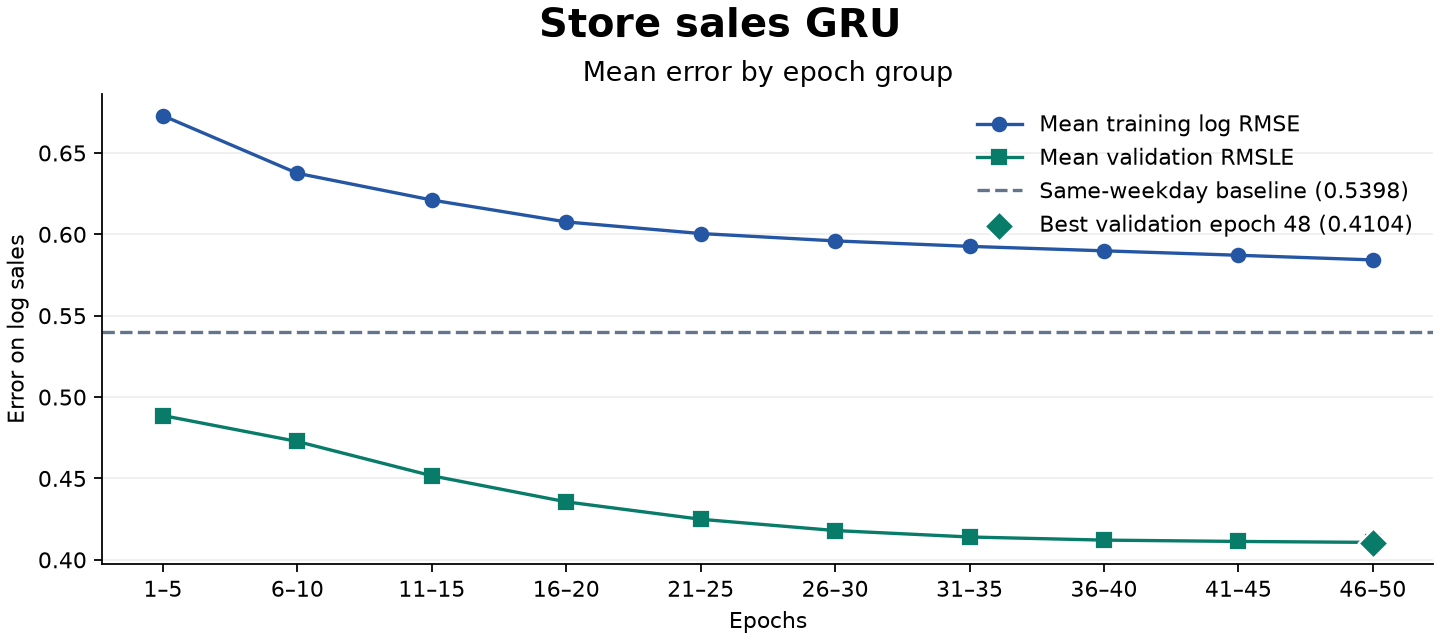

Saved plot to D:\Coding\yumeko\data\output\transactions-calendar-holidays-oil-store-last_year-mean-imputed-gru-32\training_performance.png


In [16]:
# Plot mean training and validation error in groups of five epochs.
epochs_per_group = 5
epoch_values, train_curve, validation_curve = np.asarray(history).T
epoch_numbers = epoch_values.astype(int)
group_boundaries = np.arange(epochs_per_group, len(epoch_numbers), epochs_per_group)
grouped_epochs = np.split(epoch_numbers, group_boundaries)
train_means = [group.mean() for group in np.split(train_curve, group_boundaries)]
validation_means = [group.mean() for group in np.split(validation_curve, group_boundaries)]
group_positions = np.arange(len(grouped_epochs))
group_labels = [
    str(group[0]) if len(group) == 1 else f"{group[0]}–{group[-1]}"
    for group in grouped_epochs
]
best_group = (best_epoch - 1) // epochs_per_group

fig, learning = plt.subplots(figsize=(9, 4), layout="constrained")
fig.suptitle("Store sales GRU", fontsize=18, fontweight="bold")

learning.plot(
    group_positions, train_means, "o-", color="#2456a4",
    label="Mean training log RMSE",
)
learning.plot(
    group_positions, validation_means, "s-", color="#087b69",
    label="Mean validation RMSLE",
)
learning.axhline(
    baseline_rmsle, color="#64748b", linestyle="--",
    label=f"Same-weekday baseline ({baseline_rmsle:.4f})",
)
learning.scatter(
    best_group, best_rmsle,
    color="#087b69", marker="D", s=90, edgecolor="white", zorder=4,
    label=f"Best validation epoch {best_epoch} ({best_rmsle:.4f})",
)
learning.set(title="Mean error by epoch group", xlabel="Epochs", ylabel="Error on log sales")
learning.set_xticks(group_positions, group_labels)
learning.legend(frameon=False)

learning.spines[["top", "right"]].set_visible(False)
learning.set_axisbelow(True)
learning.grid(axis="y", alpha=0.2)

plot_path = show_and_save_plot(fig, "training_performance.png")

## Compare model and baseline errors

Use observed sales on the holdout. A positive gain means lower RMSLE for the model.

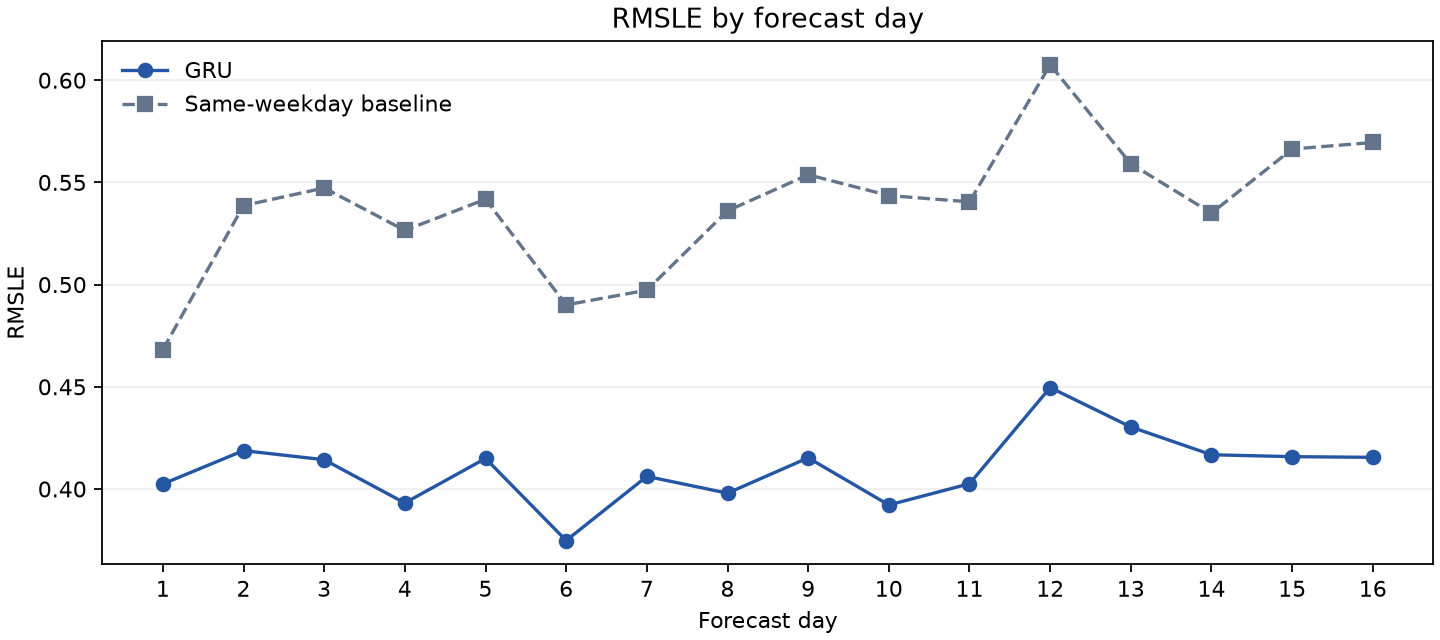

Saved plot to D:\Coding\yumeko\data\output\transactions-calendar-holidays-oil-store-last_year-mean-imputed-gru-32\rmsle_by_forecast_day.png


In [17]:
holdout = slice(split_day, split_day + horizon)
holdout_actual = log_sales[:, holdout]
holdout_observed = sales_observed[:, holdout]
forecasts_log = torch.stack([validation_log_sales, baseline_log_sales])
squared_errors = (forecasts_log - holdout_actual).square().masked_fill(~holdout_observed, 0)

model_by_day, baseline_by_day = (
    squared_errors.sum(dim=1) / holdout_observed.sum(dim=0)
).sqrt().cpu().numpy()
forecast_days = np.arange(1, horizon + 1)

fig, axis = plt.subplots(figsize=(9, 4), layout="constrained")
axis.plot(forecast_days, model_by_day, "o-", color="#2456a4", label="GRU")
axis.plot(forecast_days, baseline_by_day, "s--", color="#64748b", label="Same-weekday baseline")
axis.set(title="RMSLE by forecast day", xlabel="Forecast day", ylabel="RMSLE")
axis.set_xticks(forecast_days)
axis.grid(axis="y", alpha=0.2)
axis.legend(frameon=False)
horizon_plot_path = show_and_save_plot(fig, "rmsle_by_forecast_day.png")

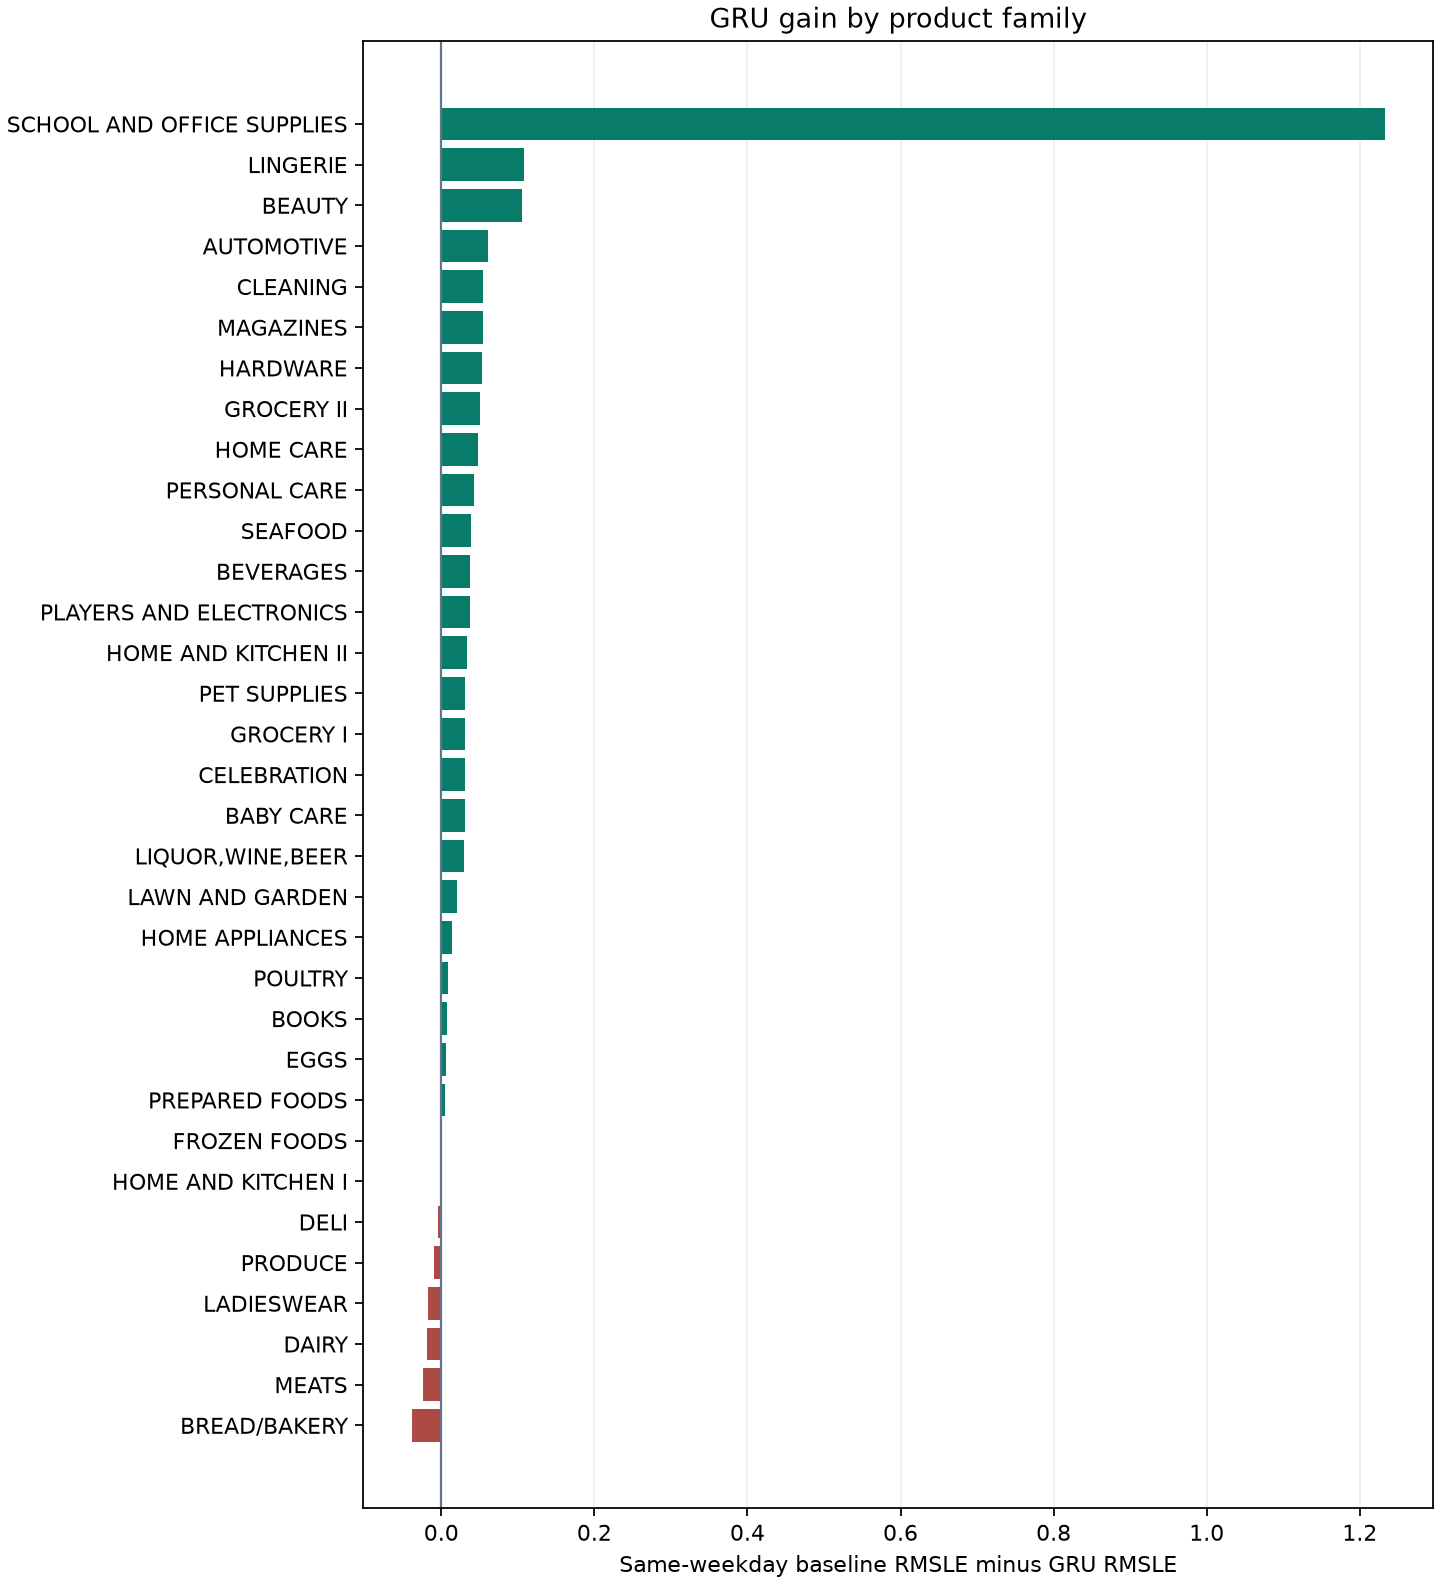

Saved plot to D:\Coding\yumeko\data\output\transactions-calendar-holidays-oil-store-last_year-mean-imputed-gru-32\rmsle_gain_by_family.png


In [18]:
# Compare forecast errors by product family
model_by_series, baseline_by_series = squared_errors.sum(dim=-1).cpu().numpy()
family_scores = (
    series_keys.with_columns(
        pl.Series("observations", holdout_observed.sum(dim=-1).cpu().numpy()),
        pl.Series("model_error", model_by_series),
        pl.Series("baseline_error", baseline_by_series),
    )
    .group_by("family")
    .agg(pl.col("observations", "model_error", "baseline_error").sum())
    .filter(pl.col("observations") > 0)
    .with_columns(
        (pl.col("model_error") / pl.col("observations")).sqrt().alias("model_rmsle"),
        (pl.col("baseline_error") / pl.col("observations")).sqrt().alias("baseline_rmsle"),
    )
    .with_columns((pl.col("baseline_rmsle") - pl.col("model_rmsle")).alias("gain"))
    .sort("gain")
)

fig, axis = plt.subplots(figsize=(9, max(5, 0.30 * family_scores.height)), layout="constrained")
gains = family_scores["gain"].to_numpy()
axis.barh(family_scores["family"].to_list(), gains, color=np.where(gains >= 0, "#087b69", "#ad4a43"))
axis.axvline(0, color="#64748b", linewidth=1)
axis.set(title="GRU gain by product family", xlabel="Same-weekday baseline RMSLE minus GRU RMSLE")
axis.set_axisbelow(True)
axis.grid(axis="x", alpha=0.2)
family_plot_path = show_and_save_plot(fig, "rmsle_gain_by_family.png")

## Inspect actual and predicted sales

Choose examples by recent sales and promotions. Each panel uses its own sales scale.

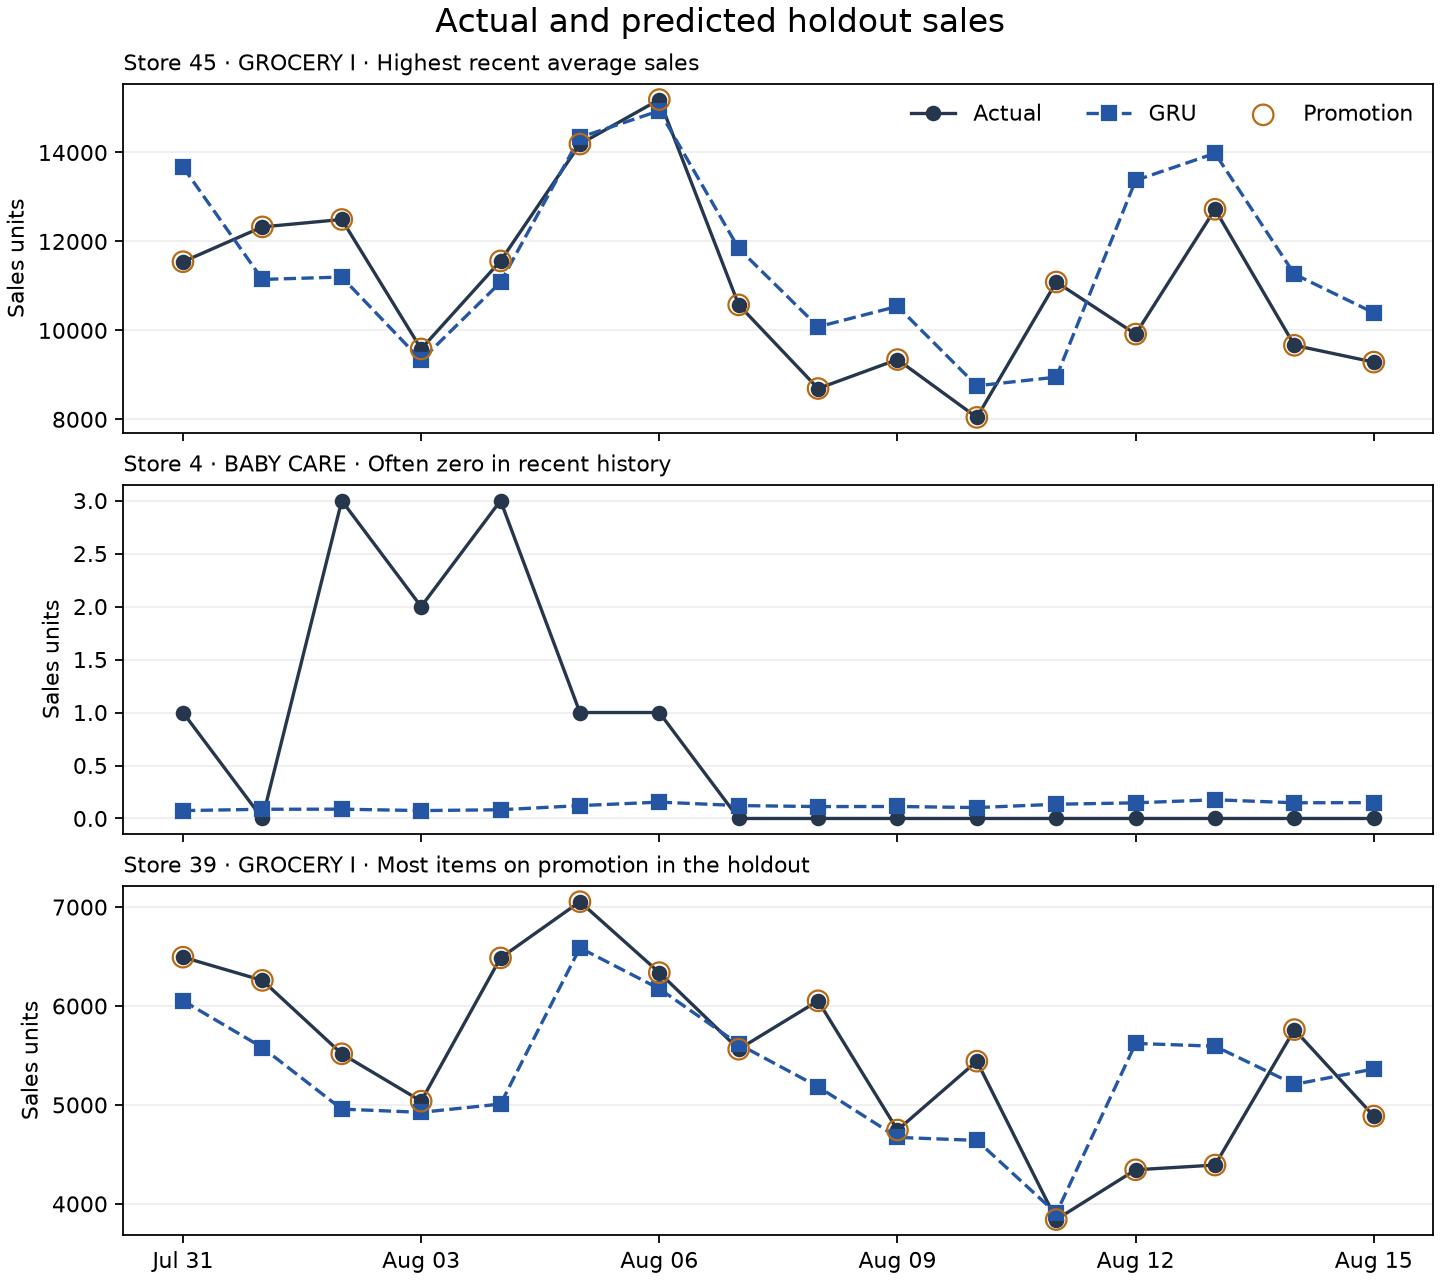

Saved plot to D:\Coding\yumeko\data\output\transactions-calendar-holidays-oil-store-last_year-mean-imputed-gru-32\actual_vs_predicted_sales.png


In [19]:
recent_dates = slice(split_day - lookback, split_day)
recent_sales = log_sales[:, recent_dates].expm1()
recent_observed = sales_observed[:, recent_dates]
recent_counts = recent_observed.sum(dim=1)
recent_average = recent_sales.masked_fill(~recent_observed, 0).sum(dim=1) / recent_counts.clamp_min(1)
zero_share = ((recent_sales == 0) & recent_observed).sum(dim=1) / recent_counts.clamp_min(1)
holdout_promotions = log_promotions[:, holdout]
promo_volume = holdout_promotions.expm1().sum(dim=1)

high_volume = recent_average.argmax().item()
sparse_scores = zero_share.masked_fill((zero_share == 1) | (recent_counts == 0), -1)
sparse_scores[high_volume] = -1
intermittent = sparse_scores.argmax().item()
promo_volume[[high_volume, intermittent]] = -1
promoted = promo_volume.argmax().item()

examples = [
    ("Highest recent average sales", high_volume),
    ("Often zero in recent history", intermittent),
    ("Most items on promotion in the holdout", promoted),
]
dates = calendar["date"][holdout].to_list()
fig, axes = plt.subplots(3, 1, figsize=(9, 8), sharex=True, layout="constrained")
fig.suptitle("Actual and predicted holdout sales", fontsize=15)
for axis, (description, series_id) in zip(axes, examples, strict=True):
    store, family = series_keys.row(series_id)
    actual = holdout_actual[series_id].expm1().masked_fill(~holdout_observed[series_id], float("nan")).cpu().numpy()
    prediction = validation_log_sales[series_id].expm1().cpu().numpy()
    promotion_days = (holdout_promotions[series_id] > 0).cpu().numpy()
    axis.plot(dates, actual, "o-", color="#26374d", label="Actual")
    axis.plot(dates, prediction, "s--", color="#2456a4", label="GRU")
    axis.scatter(
        np.asarray(dates)[promotion_days], actual[promotion_days], s=85,
        facecolors="none", edgecolors="#b96a13", zorder=3, label="Promotion",
    )
    axis.set_title(f"Store {store} · {family} · {description}", loc="left", fontsize=10)
    axis.set_ylabel("Sales units")
    axis.grid(axis="y", alpha=0.2)

axes[0].legend(frameon=False, ncol=3)
axes[-1].set_xticks(dates[::max(1, horizon // 5)])
axes[-1].xaxis.set_major_formatter(DateFormatter("%b %d"))
series_plot_path = show_and_save_plot(fig, "actual_vs_predicted_sales.png")

## Refit and forecast the test dates

Now that validation selected the number of epochs, train a fresh model using
all sales through August 15. Forecast August 16–31 and convert the predictions
from log sales back to sales units with `expm1`, the inverse of `log1p`.

In [20]:
full_origins = training_origins(test_day, include_last=True)
assert full_origins[-1] + horizon == test_day
final_context, context_scaler = fit_context(full_origins, raw_context)

print(f"Final refit for {best_epoch} epochs", flush=True)
final_model, _, _ = fit_model(full_origins, final_context, best_epoch)
test_log_sales = predict(final_model, test_day, final_context)
sales_predictions = torch.expm1(test_log_sales).cpu().numpy()
assert sales_predictions.shape == (series_count, horizon)
assert np.isfinite(sales_predictions).all() and (sales_predictions >= 0).all()

Final refit for 48 epochs
Epoch 01/48 | Train log RMSE 0.7316
Epoch 02/48 | Train log RMSE 0.6731
Epoch 03/48 | Train log RMSE 0.6542
Epoch 04/48 | Train log RMSE 0.6491
Epoch 05/48 | Train log RMSE 0.6453
Epoch 06/48 | Train log RMSE 0.6421
Epoch 07/48 | Train log RMSE 0.6394
Epoch 08/48 | Train log RMSE 0.6367
Epoch 09/48 | Train log RMSE 0.6340
Epoch 10/48 | Train log RMSE 0.6312
Epoch 11/48 | Train log RMSE 0.6283
Epoch 12/48 | Train log RMSE 0.6254
Epoch 13/48 | Train log RMSE 0.6224
Epoch 14/48 | Train log RMSE 0.6195
Epoch 15/48 | Train log RMSE 0.6164
Epoch 16/48 | Train log RMSE 0.6136
Epoch 17/48 | Train log RMSE 0.6113
Epoch 18/48 | Train log RMSE 0.6096
Epoch 19/48 | Train log RMSE 0.6080
Epoch 20/48 | Train log RMSE 0.6067
Epoch 21/48 | Train log RMSE 0.6054
Epoch 22/48 | Train log RMSE 0.6043
Epoch 23/48 | Train log RMSE 0.6031
Epoch 24/48 | Train log RMSE 0.6019
Epoch 25/48 | Train log RMSE 0.6008
Epoch 26/48 | Train log RMSE 0.5998
Epoch 27/48 | Train log RMSE 0.5987
Ep

## Save the submission and checkpoint

`submission.csv` contains one `id,sales` row for each Kaggle test example.
The notebook uses the ID order in `sample_submission.csv`. Upload this CSV to
Kaggle to get a competition score. `model.pt` stores the trained weights
and feature settings.

In [21]:
test_ids = test.sort(series_day).select("id")
forecasts = test_ids.with_columns(pl.Series("sales", sales_predictions.ravel()))
submission = sample.select("id").join(
    forecasts, on="id", how="left", validate="1:1", maintain_order="left"
)
assert submission.height == test.height
assert submission["sales"].null_count() == 0

output_dir.mkdir(parents=True, exist_ok=True)
submission.write_csv(output_dir / "submission.csv")
checkpoint = {
    "model_type": "gru",
    "gru_hidden_size": gru_hidden_size,
    "embedding_size": embedding_size,
    "baseline_weeks": baseline_weeks,
    "seed": seed,
    "epochs": best_epoch,
    "model_state_dict": {name: weight.cpu() for name, weight in final_model.state_dict().items()},
    "series_keys": series_keys.rows(),
    "lookback": lookback,
    "horizon": horizon,
    "input_width": final_model.input_width,
    "feature_groups": feature_groups,
    "impute_missing_inputs": impute_missing_inputs,
    "input_imputation": "historical_mean" if impute_missing_inputs else None,
    "transaction_window": transaction_window if "transactions" in feature_groups else None,
    "annual_lag": annual_lag if use_last_year else None,
    "calendar_features": calendar_names,
    "context_features": context_names,
    "context_scaler": context_scaler,
    "store_features": store_feature_names,
    "validation_rmsle": best_rmsle,
}
torch.save(checkpoint, output_dir / "model.pt")
print(f"Refit through {last_labeled_date}. Saved {submission.height:,} forecasts to {output_dir}.")
submission.head()

Refit through 2017-08-15. Saved 28,512 forecasts to D:\Coding\yumeko\data\output\transactions-calendar-holidays-oil-store-last_year-mean-imputed-gru-32.


id,sales
i64,f32
3000888,3.530396
3000889,0.0
3000890,6.636573
3000891,2196.545898
3000892,0.0
